# Automate Road Surface Investigation Using Deep Learning

* 🔬 Data Science
* 🥠 Deep Learning and Object Detection

## Table of Contents
* [Introduction and objective](#Introduction-and-objective)
* [Necessary imports](#Necessary-imports)
* [Prepare data that will be used for training](#Prepare-data-that-will-be-used-for-training)
* [Model training](#Model-training)
 * [Visualize training data](#Visualize-training-data)
 * [Load model architecture](#Load-model-architecture)
 * [Train a model](#Train-a-model)
 * [Detect and visualize pavement cracks in validation set](#Detect-and-visualize-pavement-cracks-in-validation-set)
 * [Save the model](#Save-the-model)
* [Model inference](#Model-inference)
    * [Detecting pavement cracks on an image](#Detecting-pavement-cracks-on-an-image)
    * [Detecting pavement cracks from video feed](#Detecting-pavement-cracks-from-video-feed)
* [Conclusion](#Conclusion)
* [References](#References)

## Introduction and objective

Deterioration of road surface due to factors including vehicle overloading, poor construction quality, over ageing, natural disasters and other climatic conditions may lead to road pavement failure. This may result in traffic slowness causing jams and vehicle damage due to cracks. This also causes problems for civic authorities who are in need to accurately identify these cracks and do the repair work. If these cracks are not repaired at early stages, cost of repair gradually increases causing unnecessary burden on exchequer. 

Traditionally, inspection of road surface is done by humans either by visually observing it or by using sophisticated machines which are expensive too. The manual approach to detect damage is not just time consuming but is also ineffective since detection of such damages requires consistent help from subject matter experts who have the ability to identify and differentiate different types of pavement failures. Artificial Intelligence supported by Deep Learning comes to the rescue. Deep learning integrated with ArcGIS plays a crucial role by automating the process. 

In this notebook, We use a great labeled dataset of asphalt distress images from the [2018 IEEE Bigdata Cup Challenge](http://cci.drexel.edu/bigdata/bigdata2018/BigDataCupChallenges.html) in order to train our model to detect as well as to classify type of road cracks. The training and test data consists of 9,053 photographs, collected from smartphone cameras, hand labeled with the presence or absence of 8 road damage categories [1].

The table below shows sample images of the dataset corresponding to each of the 8 categories of damage type. 

<table>
  <tr>
    <th>Class Name</th>
    <th>Class Description</th>    
    <th>Image</th>
  </tr>
  <tr>
      <td>D00</td>
      <td>Liner, crack, longitudinal, wheel mark part</td>
      <td><img src="data:image/PNG; base64, ..."></td>
  </tr>
  <tr>
    <td>D01</td>
    <td>Liner crack, longitudinal, construction joint part</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>
  <tr>
    <td>D10</td>
    <td>Liner crack, lateral, equal interval</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>
  <tr>
    <td>D11</td>
    <td>Liner crack, lateral, construction, joint part</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>
  <tr>
    <td>D20</td>
    <td>Alligator crack</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>
  <tr>
    <td>D40</td>
    <td>Rutting, bump, pothole, separation</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>    
  <tr>
    <td>D43</td>
    <td>White line blur</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>   
  <tr>
    <td>D44</td>
    <td>Cross walk blur</td>
    <td><img src="data:image/PNG; base64, ..."></td>
  </tr>   
</table>

Through this sample, we will walk you through step-by-step process to build robust Deep Learning solution to identify road pavement failures and eventually integrate with ArcGIS as a reusable tool.

## Necessary imports

Note: This notebook sample has not been verified to run on ArcGIS Pro. It may be possible to execute the sample within ArcGIS Pro if the libraries it requires can be installed using the [Package Manager](https://pro.arcgis.com/en/pro-app/latest/arcpy/get-started/what-is-conda.htm). If the deep learning frameworks are required, follow [this documentation](https://pro.arcgis.com/en/pro-app/latest/help/analysis/deep-learning/install-deep-learning-frameworks.htm) for more guidance.

In [1]:
# Restart the kernel after installation is complete
!pip install opencv-python==4.0.1.24

In [2]:
import pandas as pd
import os
import shutil
from pathlib import Path

from arcgis.gis import GIS
from arcgis.features import GeoAccessor
from arcgis.learn import SingleShotDetector, prepare_data

## Prepare data that will be used for training

You can download pavement cracks data from the following link: https://developers.arcgis.com/python/latest/samples/automate-road-surface-investigation-using-deep-learning/. Extract the downloaded file and run the code below to prepare data in a format that deep learning models expect.

In [3]:
# Please uncomment the following code to prepare your training data.

# input_path = Path(input("Enter the path where you extracted data: "))
# output_path = Path(input("Enter the path where you want to create training data: "))
# try:
#     if not os.path.exists(output_path/'images') and os.path.exists(output_path/'labels'):
#         os.mkdir(output_path/'images')
#         os.mkdir(output_path/'labels')
# except: raise
# for fl in os.listdir(input_path):
#     if not(fl.startswith(".")):
#         for f in os.listdir(input_path/fl/'Annotations'):
#             if not(f.startswith(".")):
#                 img_name = f.split('.')[0] + '.jpg'
                
#                 shutil.copyfile(input_path/fl/'JPEGImages'/img_name, output_path/'images'/img_name)
#                 shutil.copyfile(input_path/fl/'Annotations'/f, output_path/'labels'/f)

## Model training

You change the path to your own training data folder that contains "images" and "labels" folder.

In [4]:
gis = GIS('home')

<Item title:"automate_road_surface_investigation_using_deep_learning" type:Image Collection owner:api_data_owner>
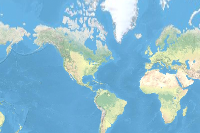

In [5]:
training_data = gis.content.get('9c7274bbfac343f3aef33f2dc1ff4baf')
training_data

In [6]:
filepath = training_data.download(file_name=training_data.name)

In [7]:
import zipfile
with zipfile.ZipFile(filepath, 'r') as zip_ref:
    zip_ref.extractall(Path(filepath).parent)

In [8]:
data_path = Path(os.path.join(os.path.splitext(filepath)[0]))

``prepare_data`` function takes path to training data and creates a fastai databunch with specified transformation, batch size, split percentage,etc. 

In [9]:
data = prepare_data(data_path,
                    batch_size=8,
                    chip_size=500,
                    seed=42,
                    dataset_type='PASCAL_VOC_rectangles')

We can use the ``classes`` attribute of the data object to get information about the number of classes.

In [10]:
data.classes 

['background', 'D00', 'D01', 'D10', 'D11', 'D20', 'D30', 'D40', 'D43', 'D44']

### Visualize training data

To get a sense of what the training data looks like, ``arcgis.learn.show_batch()`` method randomly picks a few training chips and visualize them.

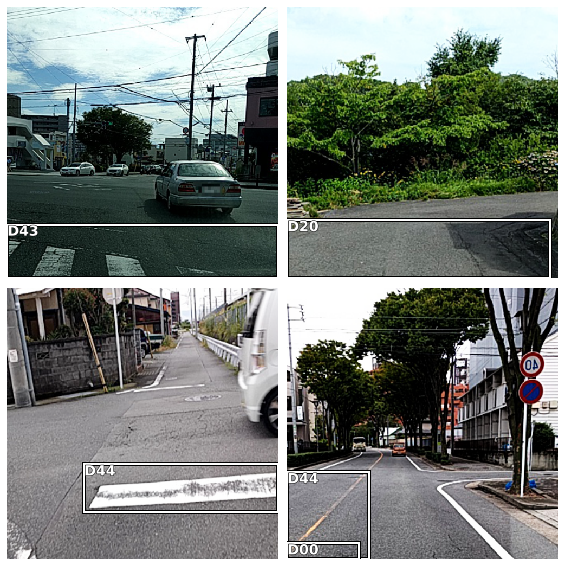

In [11]:
data.show_batch(rows=2)

### Load model architecture

``arcgis.learn`` provides the ``SingleShotDetector`` (SSD) model for object detection tasks, which is based on a pretrained convnet, like ResNet that acts as the 'backbone'. More details about SSD can be found [here](https://developers.arcgis.com/python/guide/how-ssd-works/).

We will use the ``SingleShotDetector`` to train the damage detection model with backbones as ``resnet101``. 

In [12]:
ssd = SingleShotDetector(data, backbone='resnet101',focal_loss=True)

Let us have a look at the results of the untrained model.

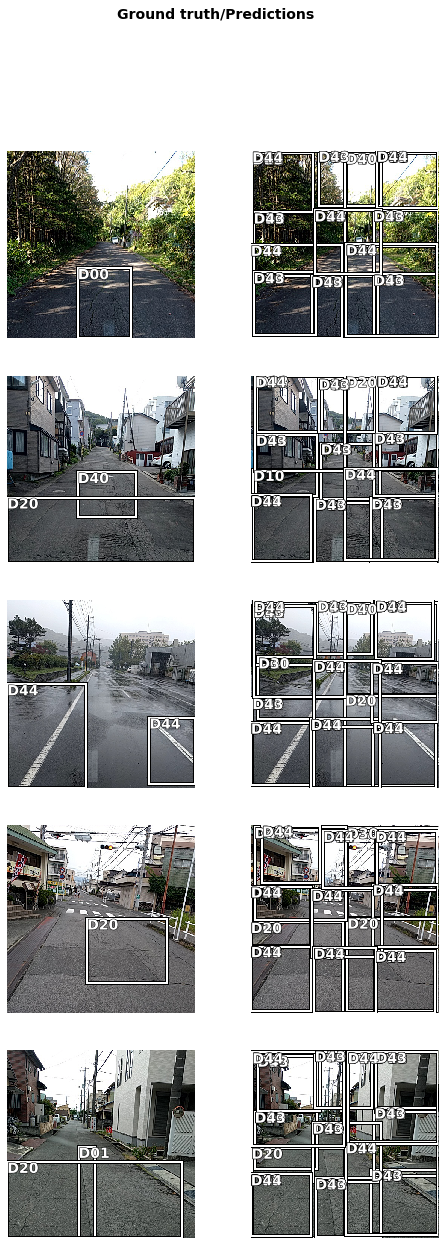

In [13]:
ssd.show_results(thresh=0.2)

We see that the model is randomly detecting the road cracks. In order to give good results our model needs to be trained. 

Learning rate is one of the most important hyperparameters in model training. We will use the ``lr_find()`` method to find an optimum learning rate at which we can train a robust model fast enough.

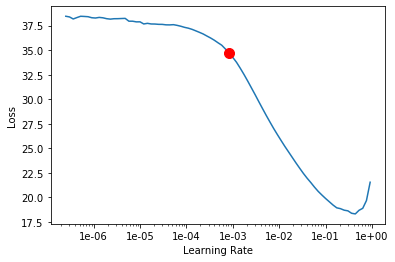

0.0008317637711026709

In [14]:
lr = ssd.lr_find()
lr

### Train a model

Based on the suggested learning rate above, we will start training our model with 30 epochs for the sake of time.

In [15]:
ssd.fit(30, lr=lr)

epoch,train_loss,valid_loss,time
0,3.916756,3.534273,07:47
1,2.189290,1.960024,07:48
2,1.913575,1.737066,07:45
3,1.727438,1.574788,07:44
4,1.587650,2.134769,07:31
5,1.508131,1.415902,07:46
6,1.400807,5.037269,07:48
7,1.382145,1.719041,07:48
8,1.375488,4.048904,07:43
9,1.303755,1.848563,07:50


The graph below plots training and validation losses. 

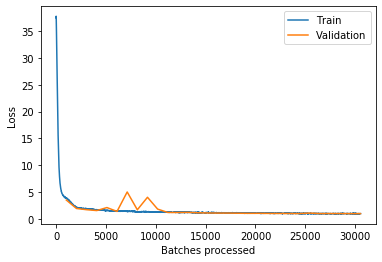

In [16]:
ssd.learn.recorder.plot_losses()

``average_precision_score`` method computes average precision on the validation set for each class.

In [17]:
ssd.average_precision_score() 

{'D00': 0.5585359730352724,
 'D01': 0.7302843487881194,
 'D10': 0.2577634234076642,
 'D11': 0.14445632230490446,
 'D20': 0.7623061137618858,
 'D30': 0.0,
 'D40': 0.16982323703158553,
 'D43': 0.813513353090408,
 'D44': 0.6490994066172426}

We can see the model accuracy for each class of our validation data. The model is giving varying results. 
Let's us dig deeper to find the reason for model to preform better on one class in comparison to the other. 
This will also help us understand why D30 class has zero average precision score. 

In [18]:
# Calculate the number of images of each classs in training data
all_classes = []
for i, bb in enumerate(data.train_ds.y):
    all_classes += bb.data[1].tolist()
    
df = pd.value_counts(all_classes, sort=False)
df.index = [data.classes[i] for i in df.index] 
df   

D43     753
D00    2477
D44    3369
D01    3418
D10     677
D11     574
D20    2290
D30      22
D40     369
dtype: int64

We have only 22 images for training our model to detect class D30 which is very less. Thus, the model is giving poor score for this specific class. 

### Detect and visualize pavement cracks in validation set

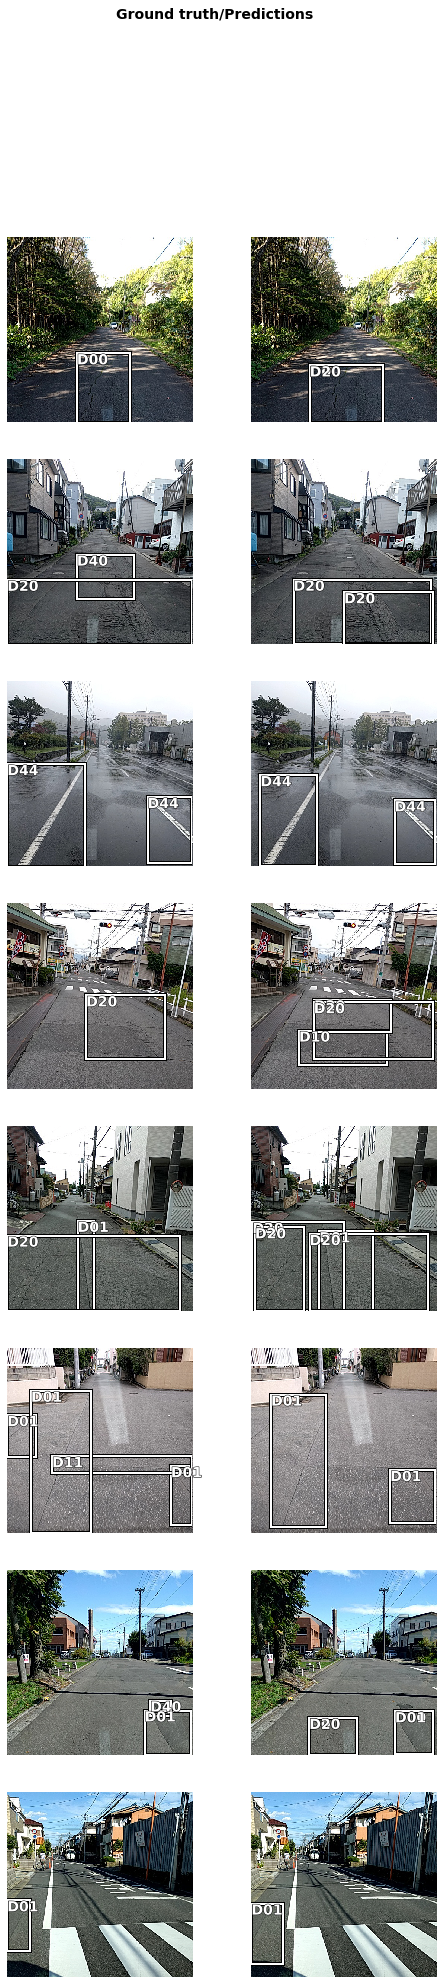

In [19]:
ssd.show_results(rows=10, thresh=0.2, nms_overlap=0.5)

### Save the model

As we can see, with 30 epochs, we are already seeing reasonable results. Further improvment can be acheived through more sophisticated hyperparameter tuning. Let's save the model for further training or inference later. The model should be saved into a models folder in your folder. By default, it will be saved into your data_path that you specified in the very beginning of this notebook.

In [20]:
ssd.save(str(data_path / 'pavement-cracks-model-resnet101'))

## Model inference

We will do model inference using the two methods: `predict` and `predict_video`. Let's get the data required to predict on image and video.

<Item title:"pavement_cracks_data_inference" type:Image Collection owner:api_data_owner>
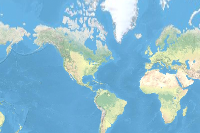

In [21]:
inference_data = gis.content.get('92a75cec191e4dbbb53067761287b977')
inference_data

In [22]:
inf_data_path = inference_data.download(file_name=inference_data.name)

In [23]:
import zipfile
with zipfile.ZipFile(inf_data_path, 'r') as zip_ref:
    zip_ref.extractall(Path(inf_data_path).parent)

In [24]:
img_file = os.path.join(os.path.splitext(inf_data_path)[0], 'test_img.jpg')
video_file = os.path.join(os.path.splitext(inf_data_path)[0], 'test_video.mp4')
metadata_file = os.path.join(os.path.splitext(inf_data_path)[0], 'metadata.csv')

### Detecting pavement cracks on an image

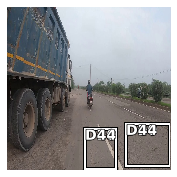

In [25]:
bbox_data = ssd.predict(img_file, threshold=0.1, visualize=True)

### Detecting pavement cracks from video feed

In [26]:
ssd.predict_video(input_video_path=video_file, 
                  metadata_file=metadata_file, 
                  visualize=True, 
                  resize=True)

## Publish results to your GIS

The `predict_video` function also updates the metadata file provided in csv format with the detections at each frame. We will now read this csv using pandas and publish it as a layer on our GIS.

In [27]:
import pandas as pd
df = pd.read_csv(metadata_file)
df

,UNIX Time Stamp,Sensor Latitude,Sensor Longitude,Sensor True Altitude,Frame Center Latitude,Frame Center Longitude,Frame Center Elevation,vmtilocaldataset
0,1.564889e+15,28.412995,77.162906,294.736633,28.412995,77.162906,294.736633,\n
1,1.564889e+15,28.412995,77.162904,294.729656,28.412995,77.162904,294.729656,\n
2,1.564889e+15,28.412996,77.162902,294.722680,28.412996,77.162902,294.722680,\n
3,1.564889e+15,28.412997,77.162901,294.715703,28.412997,77.162901,294.715703,\n
4,1.564889e+15,28.412997,77.162899,294.708546,28.412997,77.162899,294.708546,\n
...,...,...,...,...,...,...,...,...
1794,1.564889e+15,28.414831,77.159583,278.085715,28.414831,77.159583,278.085715,NaN
1795,1.564889e+15,28.414831,77.159581,278.076278,28.414831,77.159581,278.076278,NaN
1796,1.564889e+15,28.414830,77.159578,278.066841,28.414830,77.159578,278.066841,NaN
1797,1.564889e+15,28.414830,77.159576,278.057561,28.414830,77.159576,278.057561,NaN


The code below removes rows from the DataFrame with no detections and also creates a new columns which contains count of the number of detections at each frame.

In [28]:
# Handle NAN and '\n' values
df.vmtilocaldataset = df.vmtilocaldataset.str.strip()
df.loc[df.vmtilocaldataset == '', 'vmtilocaldataset'] = ''
df['count'] = ( df['vmtilocaldataset'].str.split(';').str.len().fillna(1) - 1)

In [29]:
fps = 60
a = (pd.Series(df.index.values) / fps)
a = (a - .49).round().abs()
df['group'] = a

In [30]:
# Get index of row with max detections in each group
max_detection_idxes = df[['group', 'count']].groupby('group').idxmax()['count'].values

In [31]:
# Extract rows for the indexes
df_flt = df.iloc[max_detection_idxes]

In [32]:
df_flt.drop(df_flt.loc[df['count']==0].index, inplace=True)

In [33]:
sdf = GeoAccessor.from_xy(df_flt, 'Sensor Longitude', 'Sensor Latitude')

In [34]:
cracks_lyr = gis.content.import_data(sdf, title='crack points')

In [35]:
cracks_lyr

<Item title:"crack points" type:Feature Layer Collection owner:demos_deldev>

In [36]:
m1 = gis.map('Haryana, India')
m1

In [37]:
m1.basemap.basemap = "satellite"

In [38]:
m1.content.add(cracks_lyr)

In [ ]:
rend_manager = m1.content.renderer(0)
smm = rend_manager.smart_mapping()
smm.class_breaks_renderer(break_type="size", field="count_")

## Conclusion

In this notebook, we learnt how civic authorities can automate road surface investigation using deep learning in order to make policy decisions. This will not only help in repairing exisiting cracks but may prevent pavement failures in future.

## References

[1] Hiroya Maeda, et al. "Road Damage Detection Using Deep Neural Networks with Images Captured Through a Smartphone", 1801.09454, arXiv, 2018
